# Steam 游戏数据分析 · 第二阶段：哪些因素和好评率有关？

第一阶段发现，不同价位的游戏好评率不一样。但价格贵的游戏往往评价也多、类型也不同，这些因素会混在一起。

**这一阶段做两件事：**
1. 逐个看类型、热度（评价数）、发行年份与好评率的关系（单因素分析）
2. 用**多元线性回归**同时控制这些因素，检验价格的影响是否仍然存在

分析对象：评价数 ≥ 10、发行于 2008–2025 年的游戏（理由见第一阶段）。

## 1. 读取并清洗数据（与第一阶段相同的步骤）

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from pathlib import Path

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
BLUE = "#1F5FA8"
ORANGE = "#C2410C"

df = pd.read_parquet("data/games.parquet")
df = df[df["name"].str.strip() != ""].drop_duplicates(subset="appID")
df["release_date"] = pd.to_datetime(df["release_date"], format="mixed", errors="coerce")
df["year"] = df["release_date"].dt.year
df["total_reviews"] = df["positive"] + df["negative"]
df["positive_rate"] = np.where(df["total_reviews"] > 0,
                               df["positive"] / df["total_reviews"], np.nan)

rated = df[(df["total_reviews"] >= 10) & df["year"].between(2008, 2025)].copy()
overall_median = rated["positive_rate"].median()
print(f"分析样本：{len(rated):,} 款游戏，好评率中位数 {overall_median:.1%}")

分析样本：56,473 款游戏，好评率中位数 81.2%


## 2. 图 5：不同类型的好评率

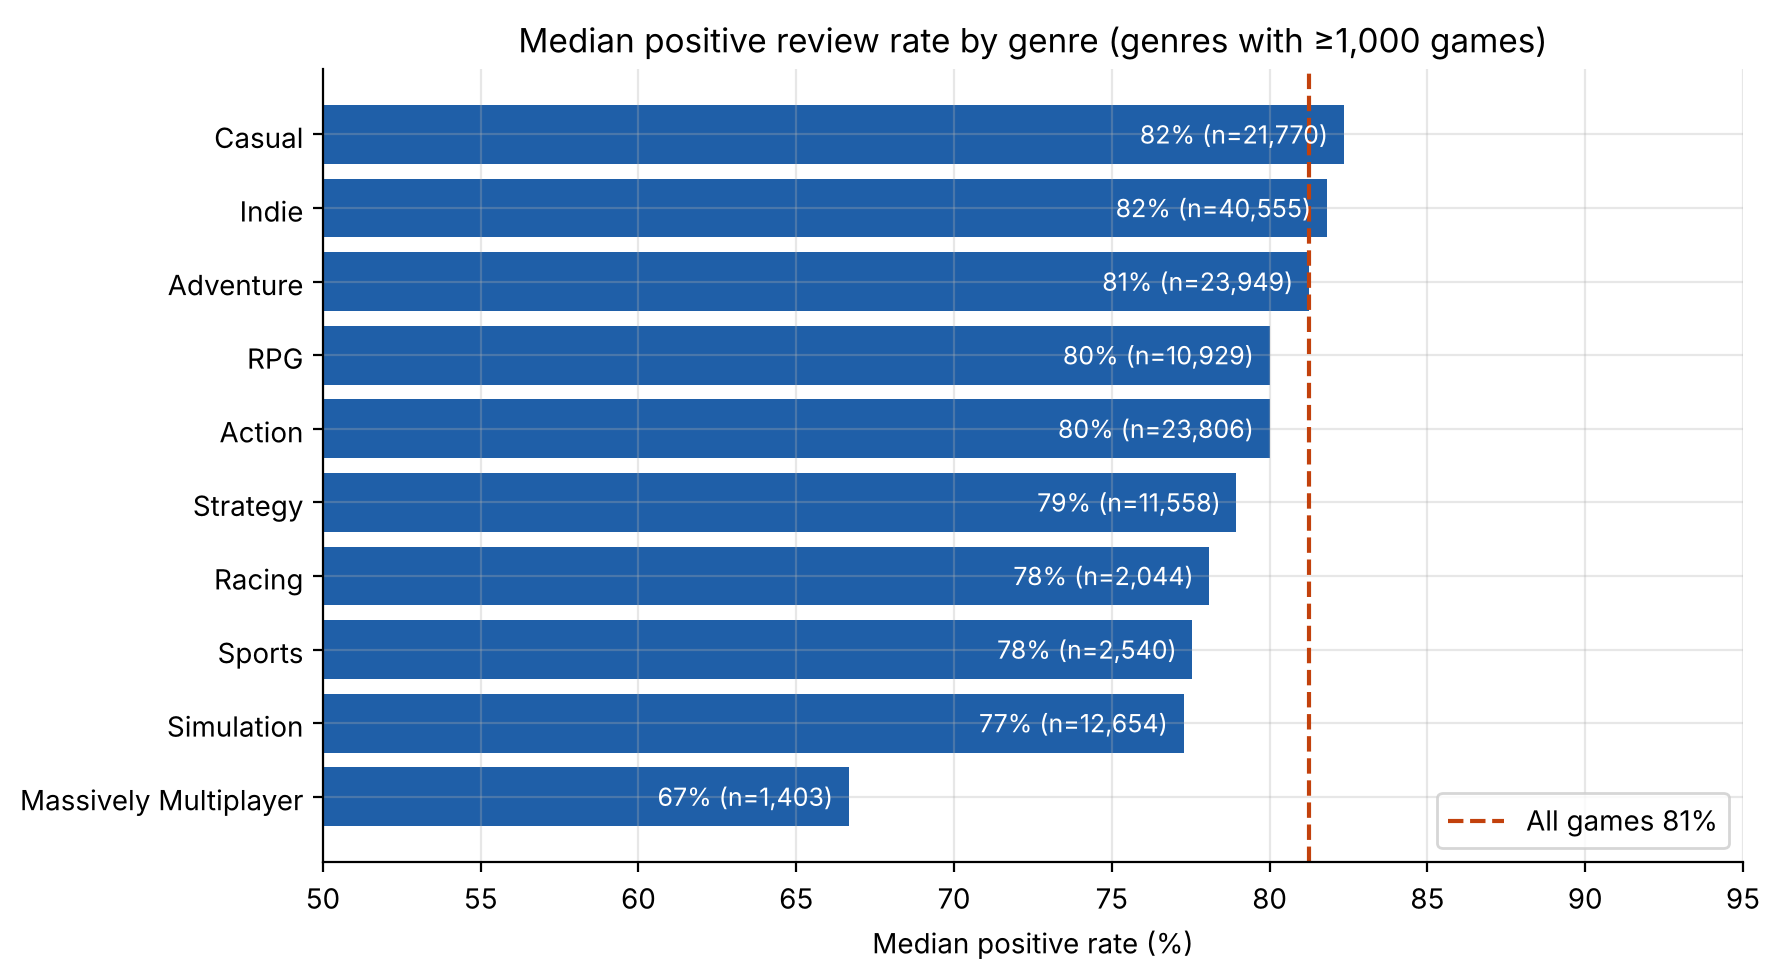

,median,count
genres,,
Massively Multiplayer,0.666667,1403
Simulation,0.772727,12654
Sports,0.775549,2540
Racing,0.780917,2044
Strategy,0.789515,11558
Action,0.800000,23806
RPG,0.800000,10929
Adventure,0.812500,23949
Indie,0.818182,40555


In [2]:
# 一款游戏可能有多个类型，explode 后每个类型各算一次
by_genre = rated.explode("genres")
by_genre = by_genre[~by_genre["genres"].isin(["Free To Play", "Early Access"])]

genre_stats = (by_genre.groupby("genres")["positive_rate"]
               .agg(["median", "count"])
               .query("count >= 1000")          # 只看样本足够多的类型
               .sort_values("median"))

fig, ax = plt.subplots()
ax.barh(genre_stats.index, genre_stats["median"] * 100, color=BLUE)
ax.axvline(overall_median * 100, color=ORANGE, linestyle="--", label=f"All games {overall_median:.0%}")
for i, (m, n) in enumerate(zip(genre_stats["median"], genre_stats["count"])):
    ax.text(m * 100 - 0.5, i, f"{m:.0%} (n={n:,})", va="center", ha="right", fontsize=9, color="white")
ax.set_xlim(50, 95)
ax.set_title("Median positive review rate by genre (genres with ≥1,000 games)")
ax.set_xlabel("Median positive rate (%)")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIG_DIR / "05_rating_by_genre.png", dpi=150)
plt.show()

genre_stats

**观察：** 休闲（Casual）和独立（Indie）游戏好评率最高，约 82%；大型多人在线（Massively Multiplayer）最低，只有约 67%。
可能的原因：网游需要长期运营，服务器、平衡性、付费设计都容易招来差评。

## 3. 图 6：热度（评价数）与好评率

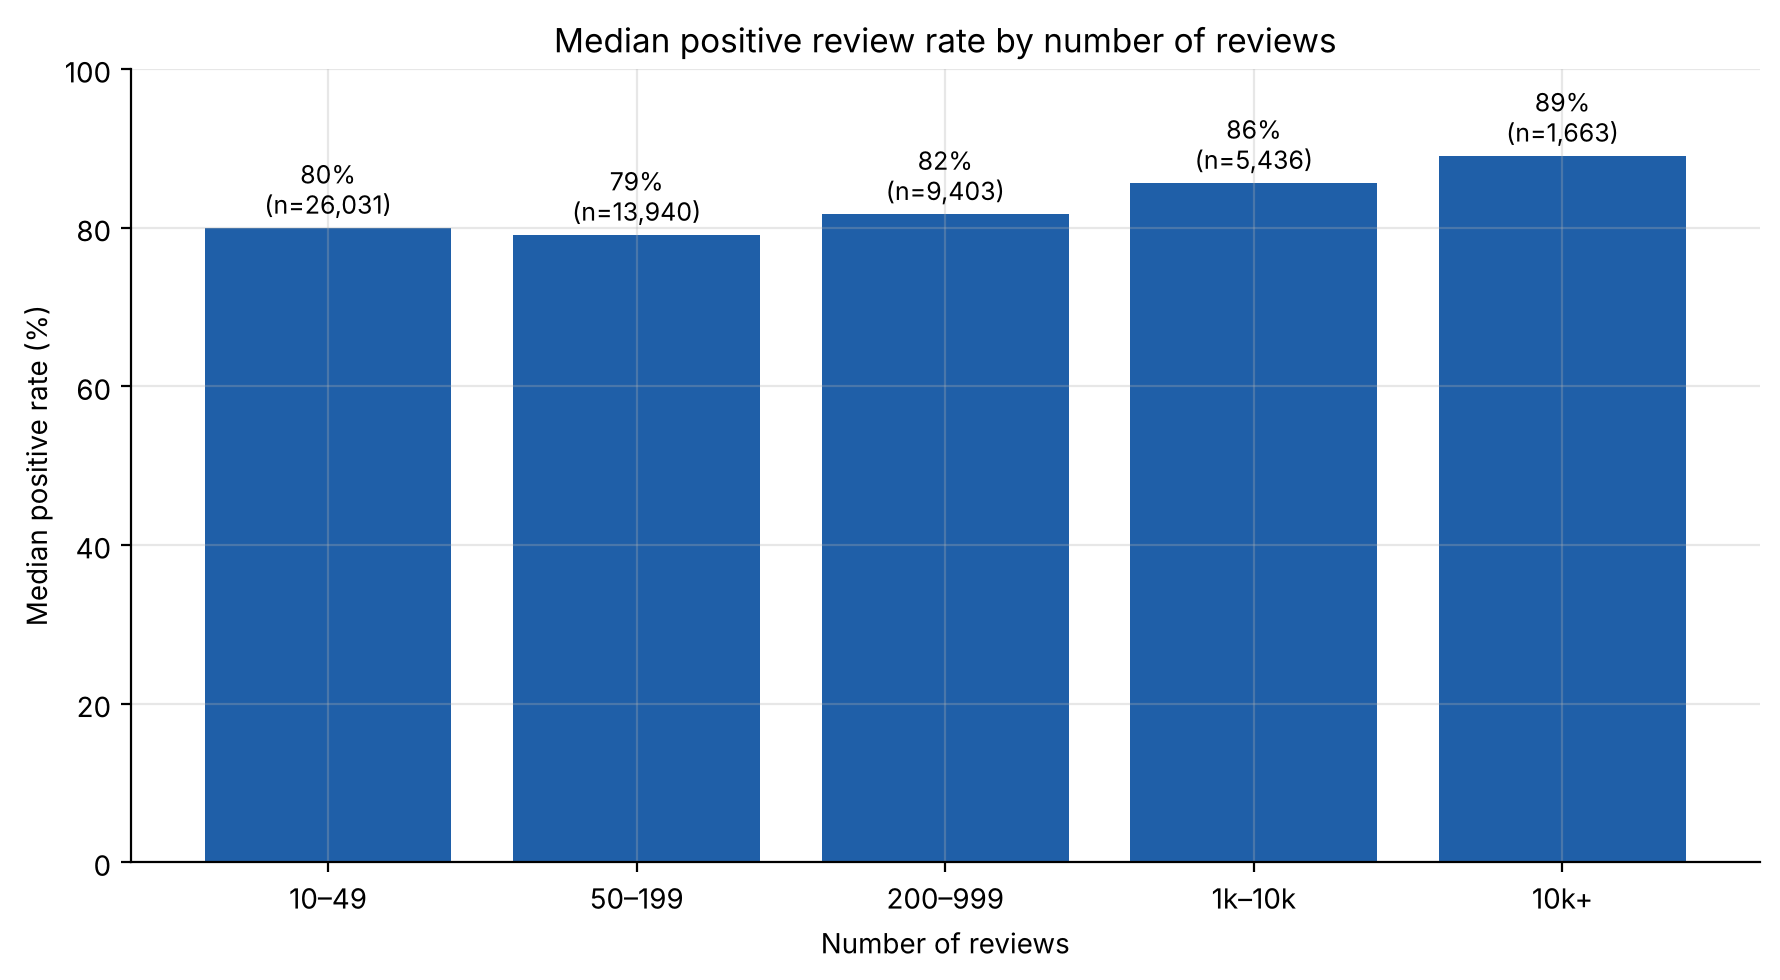

,median,count
review_band,,
10–49,0.800000,26031
50–199,0.791209,13940
200–999,0.817259,9403
1k–10k,0.856550,5436
10k+,0.890903,1663


In [3]:
review_bins = [9, 49, 199, 999, 9_999, np.inf]
review_labels = ["10–49", "50–199", "200–999", "1k–10k", "10k+"]
rated["review_band"] = pd.cut(rated["total_reviews"], bins=review_bins, labels=review_labels)

by_reviews = rated.groupby("review_band", observed=True)["positive_rate"].agg(["median", "count"])

fig, ax = plt.subplots()
ax.bar(by_reviews.index.astype(str), by_reviews["median"] * 100, color=BLUE)
for i, (m, n) in enumerate(zip(by_reviews["median"], by_reviews["count"])):
    ax.text(i, m * 100 + 1, f"{m:.0%}\n(n={n:,})", ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, 100)
ax.set_title("Median positive review rate by number of reviews")
ax.set_xlabel("Number of reviews")
ax.set_ylabel("Median positive rate (%)")
fig.tight_layout()
fig.savefig(FIG_DIR / "06_rating_by_review_count.png", dpi=150)
plt.show()

by_reviews

**观察：** 评价数超过 1,000 后好评率明显上升，1 万条以上的游戏中位数约 89%。
注意这是**相关**，不是因果：可能是好游戏吸引更多玩家，也可能是玩家多的游戏更容易得到持续更新。

## 4. 图 7：不同发行年份的好评率

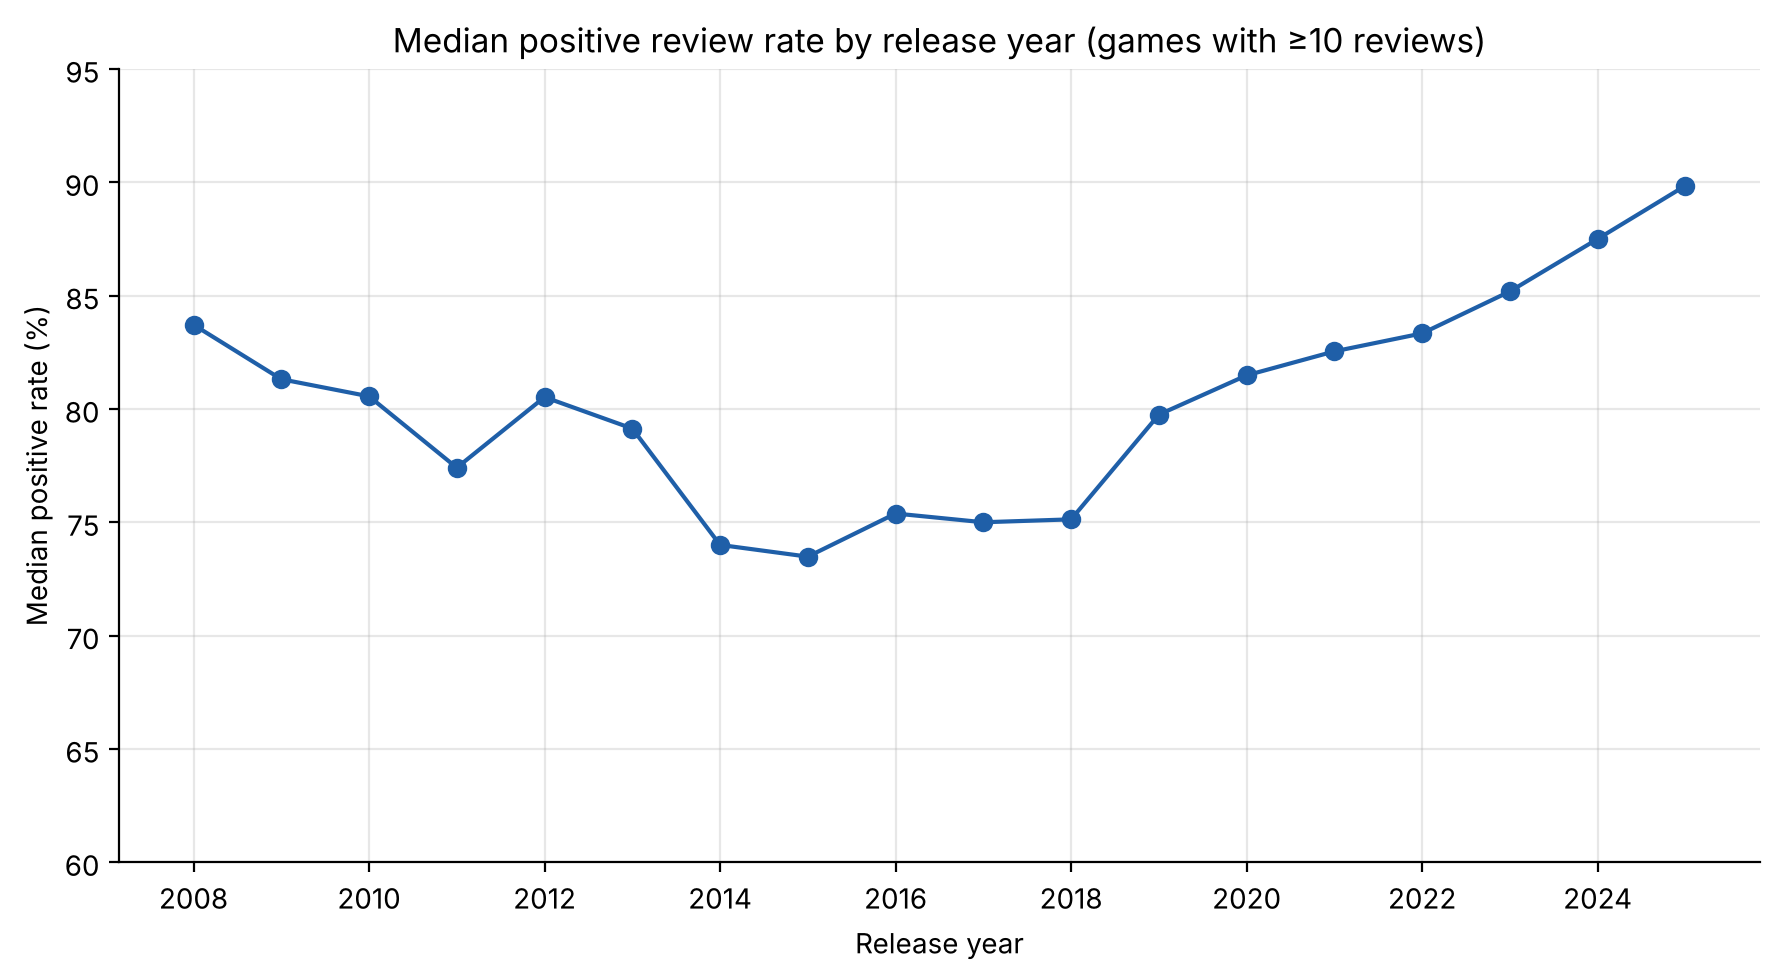

2015 年：73%；2025 年：90%


In [4]:
by_year = rated.groupby("year")["positive_rate"].agg(["median", "count"])

fig, ax = plt.subplots()
ax.plot(by_year.index, by_year["median"] * 100, marker="o", color=BLUE)
ax.set_ylim(60, 95)
ax.set_xticks(range(2008, 2026, 2))
ax.set_title("Median positive review rate by release year (games with ≥10 reviews)")
ax.set_xlabel("Release year")
ax.set_ylabel("Median positive rate (%)")
fig.tight_layout()
fig.savefig(FIG_DIR / "07_rating_by_year.png", dpi=150)
plt.show()

print(f"2015 年：{by_year.loc[2015, 'median']:.0%}；2025 年：{by_year.loc[2025, 'median']:.0%}")

**观察：** 2014–2018 年发行的游戏好评率最低（约 73–75%），之后逐年上升，2025 年约 90%。
这个结果要谨慎解读：新游戏的评价大多来自早期核心玩家，评价也还在积累中，以后可能回落。

## 5. 多元线性回归：控制其他因素后，价格还有影响吗？

单因素分析的问题是因素之间互相影响。比如 \$40 以上的游戏评价数通常很多，而评价多本身就和好评率高相关。

**回归模型：**
- 因变量：好评率（0–1）
- 自变量：价格区间（以免费游戏为基准）、评价数（取 log10）、10 个类型（是/否）、发行年份（分类变量）
- 使用稳健标准误（HC1），因为不同游戏的误差大小不一样

In [5]:
price_bins = [-0.01, 0, 4.99, 9.99, 19.99, 39.99, np.inf]
price_labels = ["Free", "<$5", "$5–10", "$10–20", "$20–40", "$40+"]
rated["price_band"] = pd.cut(rated["price"], bins=price_bins, labels=price_labels)
rated["log_reviews"] = np.log10(rated["total_reviews"])

# 为 10 个主要类型各做一个 0/1 变量
GENRES = ["Indie", "Casual", "Action", "Adventure", "Simulation",
          "Strategy", "RPG", "Sports", "Racing", "Massively Multiplayer"]
genre_cols = []
for g in GENRES:
    col = "g_" + g.replace(" ", "_")
    rated[col] = rated["genres"].apply(lambda arr: g in arr).astype(int)
    genre_cols.append(col)

formula = ("positive_rate ~ C(price_band, Treatment('Free')) + log_reviews + C(year) + "
           + " + ".join(genre_cols))
model = smf.ols(formula, data=rated).fit(cov_type="HC1")
print(f"样本量：{int(model.nobs):,}，R²：{model.rsquared:.3f}")
print(f"评价数每增加 10 倍，好评率平均高 {model.params['log_reviews'] * 100:.1f} 个百分点")

样本量：56,473，R²：0.157
评价数每增加 10 倍，好评率平均高 5.1 个百分点


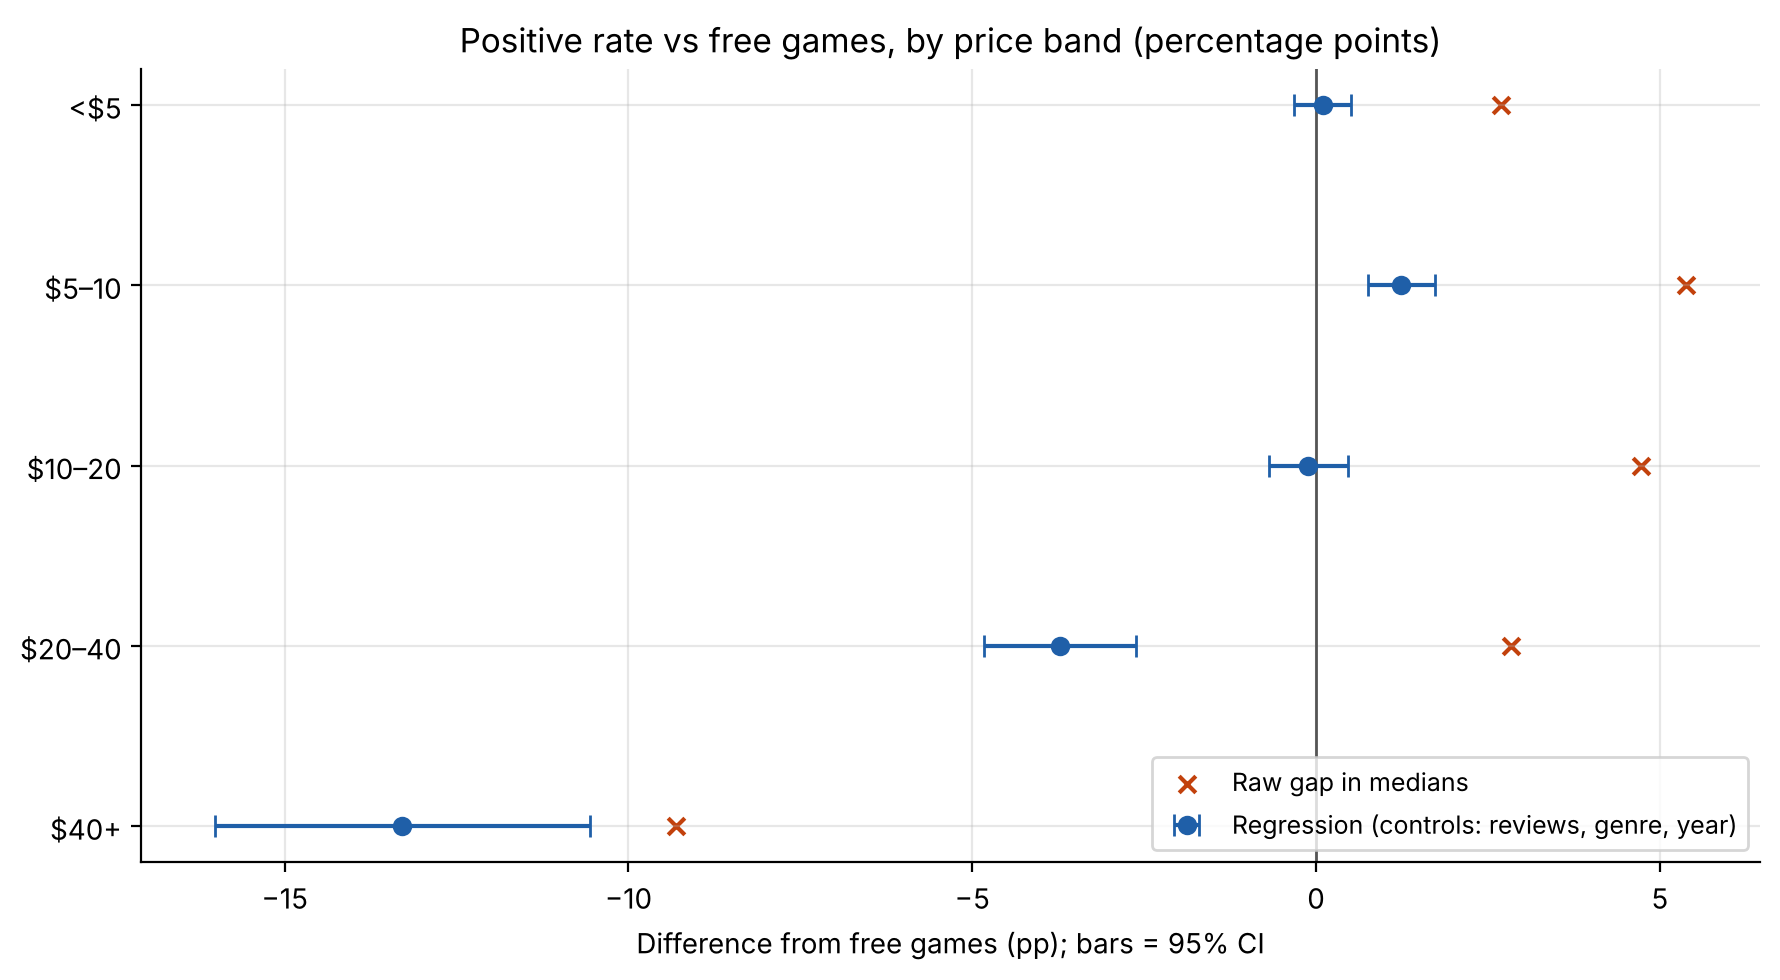

,regression_pp,ci_low,ci_high,raw_gap_pp
<$5,0.1,-0.3,0.5,2.7
$5–10,1.2,0.8,1.7,5.4
$10–20,-0.1,-0.7,0.5,4.7
$20–40,-3.7,-4.8,-2.6,2.8
$40+,-13.3,-16.0,-10.6,-9.3


In [6]:
# 取出价格区间的系数和 95% 置信区间
price_terms = [t for t in model.params.index if "price_band" in t]
coef = model.params[price_terms] * 100
ci = model.conf_int().loc[price_terms] * 100
names = [t.split("[T.")[1].rstrip("]") for t in price_terms]

# 原始差距（各价位中位数 − 免费游戏中位数），用来对比
raw_median = rated.groupby("price_band", observed=True)["positive_rate"].median() * 100
raw_gap = (raw_median - raw_median["Free"]).loc[names]

fig, ax = plt.subplots()
y = np.arange(len(names))
ax.errorbar(coef.values, y, xerr=[coef.values - ci[0].values, ci[1].values - coef.values],
            fmt="o", color=BLUE, capsize=4, label="Regression (controls: reviews, genre, year)")
ax.scatter(raw_gap.values, y, marker="x", color=ORANGE, label="Raw gap in medians")
ax.axvline(0, color="#555555", linewidth=1)
ax.set_yticks(y)
ax.set_yticklabels(names)
ax.invert_yaxis()   # 从便宜到贵，自上而下
ax.set_title("Positive rate vs free games, by price band (percentage points)")
ax.set_xlabel("Difference from free games (pp); bars = 95% CI")
ax.legend(loc="lower right", fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "08_price_effect_regression.png", dpi=150)
plt.show()

pd.DataFrame({"regression_pp": coef.values.round(1),
              "ci_low": ci[0].values.round(1),
              "ci_high": ci[1].values.round(1),
              "raw_gap_pp": raw_gap.values.round(1)}, index=names)

In [7]:
# 类型系数：控制价格、评价数和年份后，各类型相对"不属于该类型"的差距
genre_coef = (model.params[genre_cols] * 100).round(1)
genre_coef.index = GENRES
genre_coef.sort_values()

Massively Multiplayer   -11.6
Simulation               -6.3
Action                   -2.6
Strategy                 -2.2
RPG                      -1.9
Racing                   -1.5
Adventure                -1.4
Sports                   -0.2
Casual                    1.8
Indie                     2.2
dtype: float64

## 6. 第二阶段小结（数字以上面的输出为准）

1. **类型差异明显：** 休闲和独立游戏好评率最高（约 82%），大型多人在线游戏最低（约 67%）；控制其他因素后，MMO 标签仍对应约 −12 个百分点。
2. **越热门，口碑越好：** 评价数每增加 10 倍，好评率平均高约 5 个百分点。
3. **新游戏好评率更高：** 2014–2018 年发行的游戏最低（约 73–75%），2025 年约 90%，但新游戏评价还在积累，需要谨慎解读。
4. **价格的影响：** 控制评价数、类型和年份后，\$20 以下各价位与免费游戏相差不超过约 1 个百分点；**\$40 以上的游戏好评率低约 13 个百分点**，比原始差距（约 9 个百分点）还大。
   这说明高价游戏的低好评率不是因为"评价少"或"类型不同"，玩家对高价游戏的期待可能确实更高。

**局限：** 模型 R² 约 0.16，说明好评率主要由这些变量之外的因素决定（比如游戏本身的质量）；回归只能说明相关性，不能证明因果。
